In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/petrol-price-forecasting/sample_submission.csv
/kaggle/input/petrol-price-forecasting/train_data.csv
/kaggle/input/petrol-price-forecasting/test_data.csv


In [2]:
# load the data set
df = pd.read_csv('/kaggle/input/petrol-price-forecasting/train_data.csv')


In [3]:
df.head()

,Date,Petrol (USD)
0,6/9/2003,74.59
1,6/16/2003,74.47
2,6/23/2003,74.42
3,6/30/2003,74.35
4,7/7/2003,74.28


In [4]:
df.tail()

,Date,Petrol (USD)
808,12/3/2018,124.30
809,12/10/2018,122.37
810,12/17/2018,121.02
811,12/24/2018,120.61
812,12/31/2018,120.18


In [5]:
df.shape

(813, 2)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 813 entries, 0 to 812
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          813 non-null    object 
 1   Petrol (USD)  811 non-null    float64
dtypes: float64(1), object(1)
memory usage: 12.8+ KB


In [7]:
df.describe()

,Petrol (USD)
count,811.000000
mean,110.330481
std,19.241182
min,74.210000
25%,94.525000
50%,112.420000
75%,128.560000
max,189.510000


In [8]:
# find the null value in the data set
def find_null_value(data):
    for i in data:
        if i == '':
            return True
    return False

print(find_null_value(df))

False


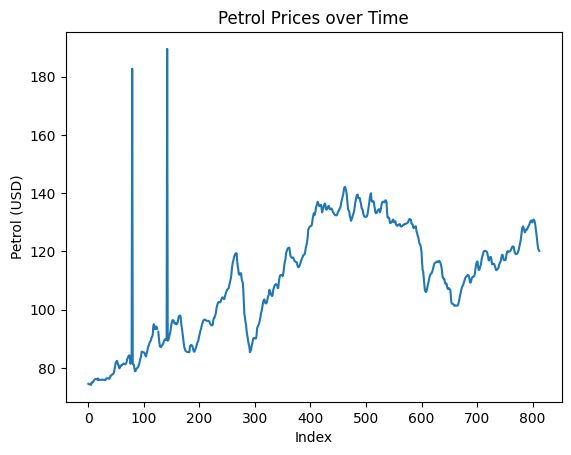

In [9]:
# plot the Petrol (USD)line chart

import matplotlib.pyplot as plt

plt.plot(df['Petrol (USD)'])
plt.xlabel('Index')
plt.ylabel('Petrol (USD)')
plt.title('Petrol Prices over Time')
plt.show()


/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/tmp/ipykernel_20/1785286140.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Petrol (USD)'])


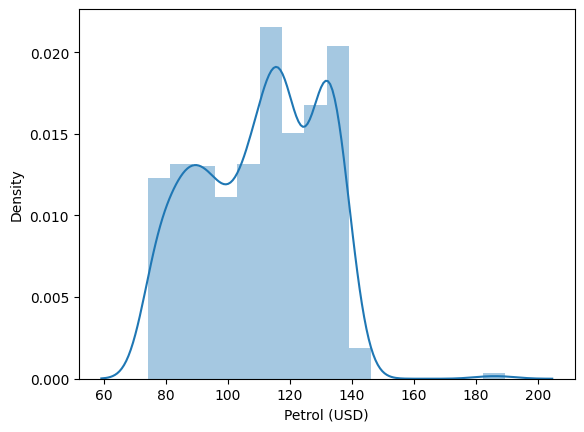

In [10]:
# plot the distribution
import seaborn as sns

sns.distplot(df['Petrol (USD)'])

# show the plot
plt.show()

In [11]:
# pip install prophet


In [12]:
from prophet import Prophet
from prophet.plot import plot_plotly, plot_components_plotly

In [13]:
# Prophet requires that your DataFrame has two columns: 'ds' and 'y'
# 'ds' should be a column of date or datetime values
# 'y' should be a column of numeric values representing your target variable

df = df.rename(columns={'Date': 'ds', 'Petrol (USD)': 'y'})
df['ds'] = pd.to_datetime(df['ds'])

In [14]:
# Create Prophet model
model = Prophet(interval_width=0.80, daily_seasonality=True)

# Fit the model to the data
model.fit(df)


16:01:08 - cmdstanpy - INFO - Chain [1] start processing
16:01:09 - cmdstanpy - INFO - Chain [1] done processing


In [15]:
## Create dataframe for predictions using test.csv
dt=pd.read_csv('/kaggle/input/petrol-price-forecasting/test_data.csv')
dt.head()

,Date,Prediction
0,1/1/2019,NaN
1,1/2/2019,NaN
2,1/3/2019,NaN
3,1/4/2019,NaN
4,1/5/2019,NaN


In [16]:
# dataframe for predictions
future =pd.DataFrame(dt['Date'])
future=future.rename(columns={'Date':'ds'})
future['ds'] = pd.to_datetime(future['ds'])
future

,ds
0,2019-01-01
1,2019-01-02
2,2019-01-03
3,2019-01-04
4,2019-01-05
5,2019-01-06
6,2019-01-07
7,2019-01-08
8,2019-01-09
9,2019-01-10


**ds** and **yhat** are column names used in the output of the Prophet library in Python for time series forecasting.

**ds** stands for "datestamp" and it represents the time axis in the dataset. It is a column containing the timestamps of the time series data, usually in a pandas datetime format.

**yhat** represents the predicted values of the time series at each timestamp. It is a column containing the predicted values of the time series data, usually in the same format as the original data.

In [17]:
# Make predictions
forecast = model.predict(future)
predict=forecast[['ds', 'yhat']]
predict

,ds,yhat
0,2019-01-01,121.212111
1,2019-01-02,125.182351
2,2019-01-03,123.080276
3,2019-01-04,123.081689
4,2019-01-05,123.110003
5,2019-01-06,123.163242
6,2019-01-07,123.111976
7,2019-01-08,121.383163
8,2019-01-09,125.519844
9,2019-01-10,123.567395


The resulting plot shows the original time series data as black points, the predicted values as a blue line, and the shaded region as a blue area around the line. The shaded region represents the uncertainty of the predictions and is calculated based on the uncertainty of the model parameters.

Overall, the prediction plot is a useful tool for visualizing the forecasted values and understanding the uncertainty of the predictions. It can help you to identify trends, patterns, and anomalies in the data, and evaluate the performance of the model. 

In [18]:
# Plot the predictions
plot_plotly(model,forecast)


In [19]:
# plot the model componets
plot_components_plotly(model, forecast)

/opt/conda/lib/python3.10/site-packages/plotly/io/_json.py:534: UserWarning:

Discarding nonzero nanoseconds in conversion.



In [20]:
# assuming `predict` is the dataframe with predicted values
submission = predict.rename(columns={'ds':'Date','yhat':'Prediction'})

# save the dataframe as a CSV file
submission.to_csv('submission.csv', index=False)

# download the CSV file
from IPython.display import FileLink
FileLink('submission.csv')

/kaggle/working/submission.csv